In [13]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [14]:
words=open("names.txt","r").read().splitlines()

In [15]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [16]:
len(words)

32033

In [17]:
stoi={s:i+1 for i,s in enumerate(sorted(set(''.join(words))))}
stoi['.']=0
itos={i:s for s,i in stoi.items()}
vocab_size=len(itos)

In [18]:
block_size=3
X,Y=[],[]
for w in words:
    
    content=[0]*block_size
    for ch in w+'.':
        ix=stoi[ch]
        X.append(content)
        Y.append(ix)
        content=content[1:]+[ix]
X=torch.tensor(X)
Y=torch.tensor(Y)

In [19]:
def datasets(words):
    block_size=3
    X,Y=[],[]
    for w in words:
        
        content=[0]*block_size
        for ch in w+'.':
            ix=stoi[ch]
            X.append(content)
            Y.append(ix)
            content=content[1:]+[ix]
    X=torch.tensor(X)
    Y=torch.tensor(Y)
    print(X.shape,Y.shape)
    return X,Y

In [20]:
import random
random.seed(42)
random.shuffle(words)
n1=int(0.8*(len(words)))
n2=int(0.9*(len(words)))
Xtr,Ytr=datasets(words[:n1])
Xdev,Ydev=datasets(words[n1:n2])
Xtest,Ytest=datasets(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [21]:
Xtr.shape,Ytr.shape

(torch.Size([182625, 3]), torch.Size([182625]))

In [22]:
g=torch.Generator().manual_seed(2147483647)
n_embd=10
n_hidden=200

C=torch.randn((vocab_size,n_embd),generator=g)
W1=torch.randn((n_embd*block_size,n_hidden),generator=g)*(5/3)/n_embd*block_size**0.5
bngain=torch.ones((1,n_hidden))
bnbias=torch.zeros((1,n_hidden))
bnmean_runnig=torch.zeros((1,n_hidden))
bnstd_runnig=torch.ones((1,n_hidden))
b1=torch.randn(n_hidden,generator=g)*0.01
W2=torch.randn((n_hidden,vocab_size),generator=g)*0.01
b2=torch.randn(vocab_size,generator=g)*0
parameters=[C,W1,W2,b1,b2,bngain,bnbias]
print(sum((p.nelement() for p in parameters)))
for p in parameters:
    p.requires_grad=True

12297


In [ ]:
lossi=[]
max_steps=200000
batch_size=32
for i in range(max_steps):
    ix=torch.randint(0,Xtr.shape[0],(batch_size,))
    xb,yb=Xtr[ix],Ytr[ix]
    emd=C[xb]
    emd_cat=emd.view(emd.shape[0],-1)
    hpreact=emd_cat@W1+b1
    bnmeani=hpreact.mean(0,keepdim=True)
    bnstdi=hpreact.std(0,keepdim=True)
    hpreact=bngain*(hpreact-bnmeani)/bnstdi+bnbias
    with torch.no_grad():
        bnmean_runnig=0.999*bnmean_runnig+bnmeani*0.001
        bnstd_runnig=0.999*bnstd_runnig+bnstdi*0.001
    h=torch.tanh(hpreact)
    logits=h@W2+b2
    loss=F.cross_entropy(logits,yb)
    
    for p in parameters:
        p.grad=None
    loss.backward()
    lr=0.1 if i<100000 else 0.01
    for p in parameters:
        p.data+=-lr*p.grad
    if i%10000==0:
        print(f'{i:7d}/{max_steps:7d} :{loss.item():.4f}')
    lossi.append(loss.log().item())


      0/ 200000 :3.3070
  10000/ 200000 :2.1851
  20000/ 200000 :2.2931
  30000/ 200000 :2.5219
  40000/ 200000 :1.9165
  50000/ 200000 :1.8136
  60000/ 200000 :2.0718
  70000/ 200000 :2.0969


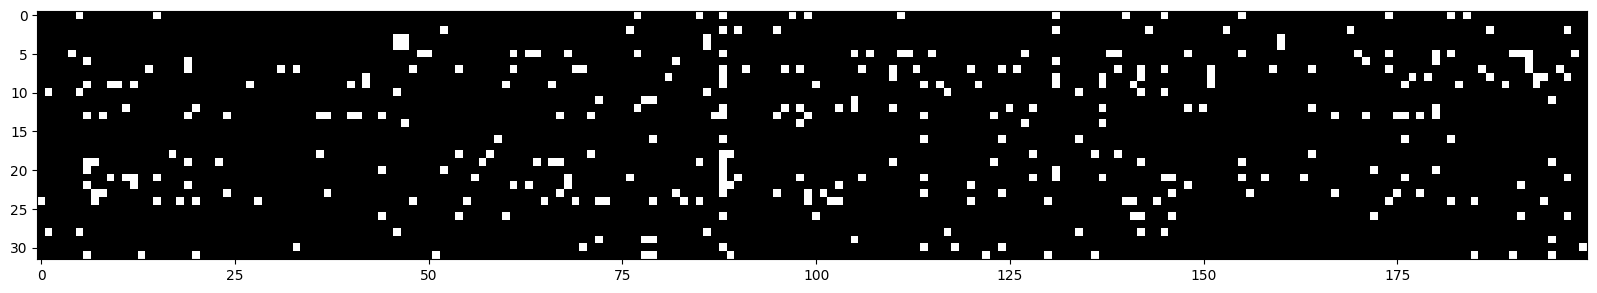

In [12]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs()>0.99,cmap='gray',interpolation='nearest')

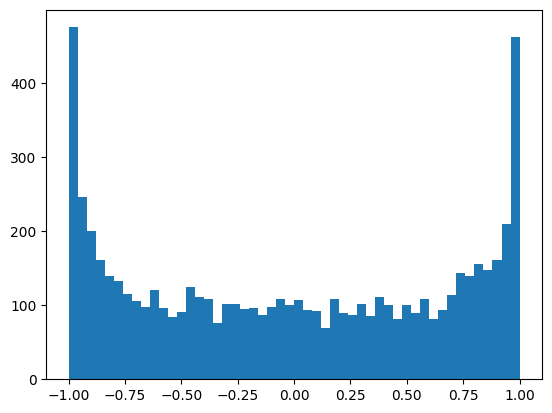

In [146]:
plt.hist(h.view(-1).tolist(),50);

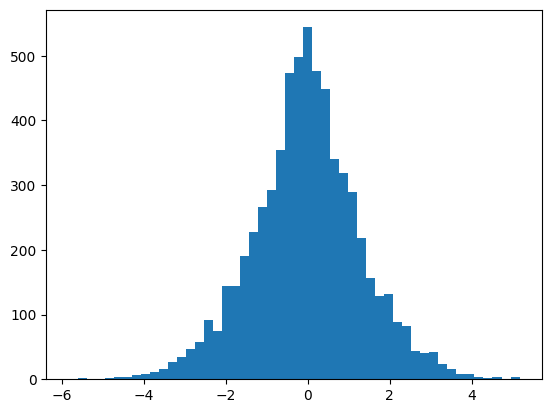

In [147]:
plt.hist(hpreact.view(-1).tolist(),50);

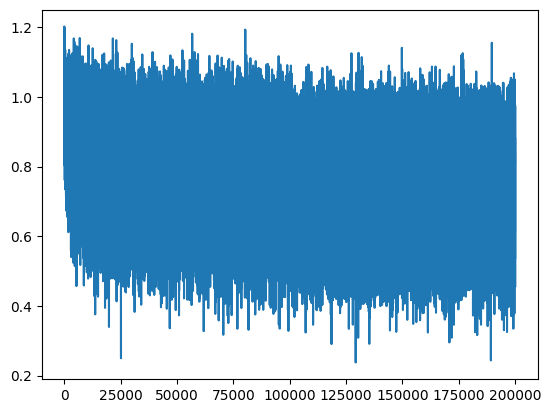

In [148]:
plt.plot(lossi)

In [149]:
with torch.no_grad():
    emd=C[Xtr]
    emd_cat=emd.view(emd.shape[0],-1)
    hpreact=emd_cat@W1+b1
    bnmean=hpreact.mean(0,keepdim=True)
    bnstd=hpreact.std(0,keepdim=True)

In [150]:
bnmean

tensor([[-2.4515, -0.3033, -1.5467,  0.9675,  0.9282,  0.9831,  2.6106, -1.2154,
          0.9206,  1.1693, -1.1316, -2.0962, -0.1757,  0.2778, -0.2711, -0.3394,
          0.3352, -2.7974, -0.3941,  1.6303, -0.6932, -0.1473, -0.6870, -0.2558,
          0.9550,  1.0332,  1.2139, -0.3227,  0.6747,  2.0801,  0.0568, -1.0376,
          0.6547, -0.4403,  0.4226, -0.0508, -0.6149, -0.2892,  0.2404,  0.4128,
         -0.1155, -1.4915, -0.3224,  0.1696,  0.6695,  0.5465,  1.2172, -1.2546,
          2.2676,  1.4045,  1.1811,  0.6948,  1.6549,  0.5434,  1.1495, -1.4905,
         -0.4676,  0.1574,  2.1153, -0.5778, -0.4175,  1.4882,  0.3362,  0.3470,
          1.7748,  1.1069, -0.3457,  0.6767, -0.6841,  0.2784, -0.3662,  0.8986,
          1.0797, -2.1549, -2.5300,  0.5743,  1.1041,  0.0268,  0.1615, -0.0044,
          0.5888,  1.7541,  1.4178,  0.5364,  0.6882, -0.5765, -0.2410, -0.4048,
          1.8770, -0.3886, -1.0933,  1.0727, -0.4104, -0.8201, -1.5575,  0.6869,
          0.1712, -0.0402,  

In [151]:
bnmean_runnig


tensor([[-2.4699, -0.2930, -1.5399,  0.9514,  0.9275,  0.9849,  2.6374, -1.2346,
          0.9028,  1.1821, -1.1487, -2.0959, -0.1846,  0.2753, -0.2694, -0.3465,
          0.3403, -2.8071, -0.3944,  1.6413, -0.7110, -0.1476, -0.6835, -0.2507,
          0.9637,  1.0422,  1.2164, -0.3383,  0.6909,  2.0849,  0.0361, -1.0400,
          0.6570, -0.4547,  0.4234, -0.0651, -0.6255, -0.3023,  0.2388,  0.4074,
         -0.1050, -1.4975, -0.3295,  0.1572,  0.6776,  0.5552,  1.2092, -1.2643,
          2.2775,  1.4204,  1.1867,  0.7099,  1.6467,  0.5507,  1.1614, -1.4998,
         -0.4740,  0.1512,  2.1254, -0.5896, -0.4204,  1.4901,  0.3385,  0.3499,
          1.7692,  1.1038, -0.3485,  0.6847, -0.6769,  0.2773, -0.3800,  0.9029,
          1.0687, -2.1658, -2.5251,  0.6000,  1.1092,  0.0349,  0.1602, -0.0065,
          0.5935,  1.7651,  1.4067,  0.5499,  0.6895, -0.5666, -0.2479, -0.4000,
          1.8878, -0.3816, -1.0993,  1.0889, -0.3994, -0.8211, -1.5694,  0.6743,
          0.1605, -0.0513,  

In [152]:
@torch.no_grad()
def split_loss(split):
    x,y={
        "train":(Xtr,Ytr),
        "val":(Xdev,Ydev),
        "test":(Xtest,Ytest)
    }[split]
    emd=C[x]
    emd_cat=emd.view(emd.shape[0],-1)
    hpreact=emd_cat@W1+b1
    hpreact=bngain*(hpreact-bnmean_runnig)/bnstd_runnig+bnbias
    h=torch.tanh(hpreact)
    logits=h@W2+b2
    loss=F.cross_entropy(logits,y)
    print(split,loss.item())
    

In [153]:
split_loss("train")
split_loss("val")

train 2.0666372776031494
val 2.1082279682159424


In [154]:
#train 2.0686540603637695
#val 2.1061017513275146

In [156]:
g=torch.Generator().manual_seed(2147483647+10)
blocksize=3
for _ in range(20):
    content=[0]*blocksize
    out=[]
    while True:
        emd=C[torch.tensor(content)]
        hpreact=emd.view(1,-1)@W1+b1
        hpreact=bngain*(hpreact-bnmean_runnig)/bnstd_runnig+bnbias
        h=torch.tanh(hpreact)
        logits=h@W2+b2
        probs=F.softmax(logits,dim=1)
        ix=torch.multinomial(probs,num_samples=1,generator=g).item()
        content=content[1:]+[ix]
        out.append(ix)
        if ix==0:
            break
    print(''.join([itos[i] for i in out]))

carmah.
amelle.
khyirri.
reviyah.
cassie.
rahnen.
deliah.
jareei.
nellara.
chaiiv.
kaleigh.
ham.
pois.
quinn.
shoir.
alianni.
waterri.
jarinix.
kaelii.
sabeed.
